In [ ]:
import re
import unicodedata
from difflib import get_close_matches

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

INPUT_FILE = 'olist_sellers_dataset.csv'
OUTPUT_DIR = '.'          # where the csv / png files are written
FUZZY_CUTOFF = 0.88       # similarity needed to treat a rare city as a typo (0-1)

In [ ]:
data = pd.read_csv(INPUT_FILE, dtype=str)
print("shape:", data.shape)

# Keep an untouched copy of every column we are going to modify.
# Reason: all corrections stay auditable and we can compare before/after.
data['zip_raw'] = data['seller_zip_code_prefix']
data['city_raw'] = data['seller_city']
data['state_raw'] = data['seller_state']

shape: (3095, 4)


In [ ]:
data['seller_zip_code_prefix'] = (
    data['seller_zip_code_prefix'].astype(str).str.strip().str.zfill(5)
)

# Original check: prefixes that are longer than 5 characters or non-numeric.
# Anything flagged here cannot be trusted as "source of truth" for the state.
bad_zip = (data['seller_zip_code_prefix'].str.len() != 5) | \
          (~data['seller_zip_code_prefix'].str.isdigit())
print("invalid zip prefixes:", bad_zip.sum())


invalid zip prefixes: 0


In [ ]:
ZIP_RANGES = [
    ('SP', 1000, 19999), ('RJ', 20000, 28999), ('ES', 29000, 29999),
    ('MG', 30000, 39999), ('BA', 40000, 48999), ('SE', 49000, 49999),
    ('PE', 50000, 56999), ('AL', 57000, 57999), ('PB', 58000, 58999),
    ('RN', 59000, 59999), ('CE', 60000, 63999), ('PI', 64000, 64999),
    ('MA', 65000, 65999), ('PA', 66000, 68899), ('AP', 68900, 68999),
    ('AM', 69000, 69299), ('RR', 69300, 69399), ('AM', 69400, 69899),
    ('AC', 69900, 69999), ('DF', 70000, 72799), ('GO', 72800, 72999),
    ('DF', 73000, 73699), ('GO', 73700, 76799), ('RO', 76800, 76999),
    ('TO', 77000, 77999), ('MT', 78000, 78899), ('MS', 79000, 79999),
    ('PR', 80000, 87999), ('SC', 88000, 89999), ('RS', 90000, 99999),
]

zip_num = pd.to_numeric(data['seller_zip_code_prefix'], errors='coerce')
state_from_zip = pd.Series(np.nan, index=data.index, dtype=object)
for uf, low, high in ZIP_RANGES:
    state_from_zip[(zip_num >= low) & (zip_num <= high)] = uf

# Normalize the original state column: uppercase + no spaces (as requested).
data['seller_state'] = data['seller_state'].astype(str).str.strip().str.upper()

# Overwrite the state ONLY where the zip gives a valid answer.
# If the zip is out of every range we keep the original state and flag it.
data['state_corrected'] = state_from_zip.notna() & (state_from_zip != data['seller_state'])
data['seller_state'] = state_from_zip.fillna(data['seller_state'])
data['state_unverified'] = state_from_zip.isna()

print("states corrected from zip:", data['state_corrected'].sum(),
      f"({data['state_corrected'].mean():.1%})")
print("states that could not be verified:", data['state_unverified'].sum())



states corrected from zip: 35 (1.1%)
states that could not be verified: 0


In [ ]:
def strip_accents(text):
    """'são paulo' -> 'sao paulo' (accents are a classic source of duplicates)."""
    return ''.join(ch for ch in unicodedata.normalize('NFKD', text)
                   if not unicodedata.combining(ch))

# Values that are NOT cities (state / country names, placeholders).
# They cannot be repaired by text rules, so they are sent to the zip fallback.
STATE_NAMES = {
    'acre', 'alagoas', 'amapa', 'amazonas', 'bahia', 'ceara', 'distrito federal',
    'espirito santo', 'goias', 'maranhao', 'mato grosso', 'mato grosso do sul',
    'minas gerais', 'para', 'paraiba', 'parana', 'pernambuco', 'piaui',
    'rio grande do norte', 'rio grande do sul', 'rondonia', 'roraima',
    'santa catarina', 'sergipe', 'tocantins_state',  # 'tocantins' is also a real MG city
    'brasil', 'brazil', 'california', 'centro',
}
UF_CODES = {u for u, _, _ in ZIP_RANGES}

# Known abbreviations found in this dataset (small, reviewed by hand).
ABBREVIATIONS = {
    'sbc': 'sao bernardo do campo',
    's jose do rio preto': 'sao jose do rio preto',
}

# Manual fixes that replace the old index-based patches (loc[517], loc[2258]).
# They are keyed by the RAW VALUE, so they still work if rows are re-ordered.
MANUAL_FIXES = {
    '04482255': 'rio de janeiro',                 # numeric value in a city cell
    'vendas@creditparts.com.br': 'maringa',       # e-mail in a city cell
}

def clean_city(raw_city, state):
    """Rule-based normalization of a single city string."""
    s = strip_accents(str(raw_city).lower().strip())          # 1. case, accents
    s = re.sub(r'\s+', ' ', s)                                # 2. repeated spaces

    if s in MANUAL_FIXES:                                     # 3. known manual fixes
        return MANUAL_FIXES[s]
    if '@' in s or s.replace(' ', '').isdigit():              # 4. e-mails / pure numbers
        return np.nan

    # 5. "city / state", "city, state, country", "city \ city", "city (district)"
    #    -> keep only the first part, which is the city.
    s = re.split(r'[/\\,(]', s)[0].strip()
    s = re.sub(r'\s+-\s+.*$', '', s).strip()                  #    "lages - sc" -> "lages"

    # 6. Trailing state code equal to the seller's OWN state:
    #    "sao paulo sp", "andira-pr", "brasilia df". Safe because we only remove
    #    the code when it matches the zip-verified state of that row.
    s = re.sub(rf'[\s\-]+{str(state).lower()}$', '', s).strip()

    s = s.replace('-', ' ')                                   # 7. "embu-guacu" -> "embu guacu"
    s = re.sub(r'\s+', ' ', s).strip()
    s = ABBREVIATIONS.get(s, s)                               # 8. abbreviations

    # 9. Values that are not cities (state names, 'sp', placeholders...)
    if s == '' or s.upper() in UF_CODES and len(s) == 2 or s in STATE_NAMES:
        return np.nan
    return s

data['seller_city'] = [clean_city(c, st) for c, st in zip(data['city_raw'], data['seller_state'])]
data['city_after_rules'] = data['seller_city']                # snapshot for the visuals
print("cities not recoverable by text rules:", data['seller_city'].isna().sum())

cities not recoverable by text rules: 11


In [ ]:
data['city_fuzzy_fixed'] = False
fuzzy_log = []

for uf, group in data.groupby('seller_state'):
    counts = group['seller_city'].value_counts()
    reliable = counts[counts >= 2].index.tolist()   # trusted vocabulary
    rare = counts[counts == 1].index.tolist()       # candidates for typos
    for city in rare:
        if len(city) < 6:                           # too short to compare safely
            continue
        match = get_close_matches(city, reliable, n=1, cutoff=FUZZY_CUTOFF)
        if match:
            idx = group.index[group['seller_city'] == city]
            data.loc[idx, 'seller_city'] = match[0]
            data.loc[idx, 'city_fuzzy_fixed'] = True
            fuzzy_log.append((uf, city, match[0]))

print(f"\nfuzzy corrections: {len(fuzzy_log)}  (REVIEW THIS LIST)")
for uf, old, new in fuzzy_log:
    print(f"  [{uf}] {old!r} -> {new!r}")


fuzzy corrections: 20  (REVIEW THIS LIST)
  [MG] 'belo horizont' -> 'belo horizonte'
  [PR] 'cascavael' -> 'cascavel'
  [PR] 'sao jose dos pinhas' -> 'sao jose dos pinhais'
  [SC] 'balenario camboriu' -> 'balneario camboriu'
  [SC] 'floranopolis' -> 'florianopolis'
  [SP] 'sao pauo' -> 'sao paulo'
  [SP] 'sao bernardo do capo' -> 'sao bernardo do campo'
  [SP] 'portoferreira' -> 'porto ferreira'
  [SP] 'mogi das cruses' -> 'mogi das cruzes'
  [SP] 'sando andre' -> 'santo andre'
  [SP] 'garulhos' -> 'guarulhos'
  [SP] 'sao jose do rio pret' -> 'sao jose do rio preto'
  [SP] 'sao paluo' -> 'sao paulo'
  [SP] 'ao bernardo do campo' -> 'sao bernardo do campo'
  [SP] 'sao paulop' -> 'sao paulo'
  [SP] 'scao jose do rio pardo' -> 'sao jose do rio pardo'
  [SP] 'ribeirao pretp' -> 'ribeirao preto'
  [SP] 'robeirao preto' -> 'ribeirao preto'
  [SP] 'tabao da serra' -> 'taboao da serra'
  [SP] 'riberao preto' -> 'ribeirao preto'


In [ ]:
modal_city_by_zip = (data.dropna(subset=['seller_city'])
                         .groupby('seller_zip_code_prefix')['seller_city']
                         .agg(lambda x: x.mode().iloc[0]))
missing = data['seller_city'].isna()
data.loc[missing, 'seller_city'] = data.loc[missing, 'seller_zip_code_prefix'].map(modal_city_by_zip)
data['city_from_zip'] = missing & data['seller_city'].notna()
print("\ncities filled from zip fallback:", data['city_from_zip'].sum())
# Second fallback: if the zip prefix is unique (no other seller shares it), use
# the most frequent city of the seller's STATE instead. This is an approximation,
# but it keeps the column complete, and the flag below lets us trace these rows.
still_missing = data['seller_city'].isna()
modal_city_by_state = (data.dropna(subset=['seller_city'])
                           .groupby('seller_state')['seller_city']
                           .agg(lambda x: x.mode().iloc[0]))
data.loc[still_missing, 'seller_city'] = data.loc[still_missing, 'seller_state'].map(modal_city_by_state)
data['city_from_state'] = still_missing & data['seller_city'].notna()
print("cities filled from state fallback:", data['city_from_state'].sum())
print("cities still missing:", data['seller_city'].isna().sum())

# Validation flag (we do NOT overwrite): a city that disagrees with the most
# common city of its own zip prefix. Only meaningful if the prefix appears 2+ times.
zip_counts = data['seller_zip_code_prefix'].map(data['seller_zip_code_prefix'].value_counts())
modal_city_by_zip = (data.dropna(subset=['seller_city'])
                         .groupby('seller_zip_code_prefix')['seller_city']
                         .agg(lambda x: x.mode().iloc[0]))
data['city_zip_mismatch'] = (
    (zip_counts >= 2) &
    (data['seller_city'] != data['seller_zip_code_prefix'].map(modal_city_by_zip))
)
print("rows where city disagrees with its zip's usual city (review):",
      data['city_zip_mismatch'].sum())


cities filled from zip fallback: 4
cities filled from state fallback: 7
cities still missing: 0
rows where city disagrees with its zip's usual city (review): 9


In [ ]:
assert data['seller_id'].is_unique, "duplicate seller_id found"
assert data['seller_id'].str.len().eq(32).all(), "unexpected seller_id length"
assert data['seller_zip_code_prefix'].str.len().eq(5).all(), "zip prefix not 5 chars"
assert data['seller_city'].notna().all(), "some cities are still missing"
assert data['seller_state'].isin(UF_CODES).all(), "invalid state code left"
print("\ncleaning checks passed")
print("distinct cities: raw =", data['city_raw'].nunique(),
      "| after rules =", data['city_after_rules'].nunique(),
      "| final =", data['seller_city'].nunique())



cleaning checks passed
distinct cities: raw = 611 | after rules = 573 | final = 553


Text(0.5, 0, 'rows affected')

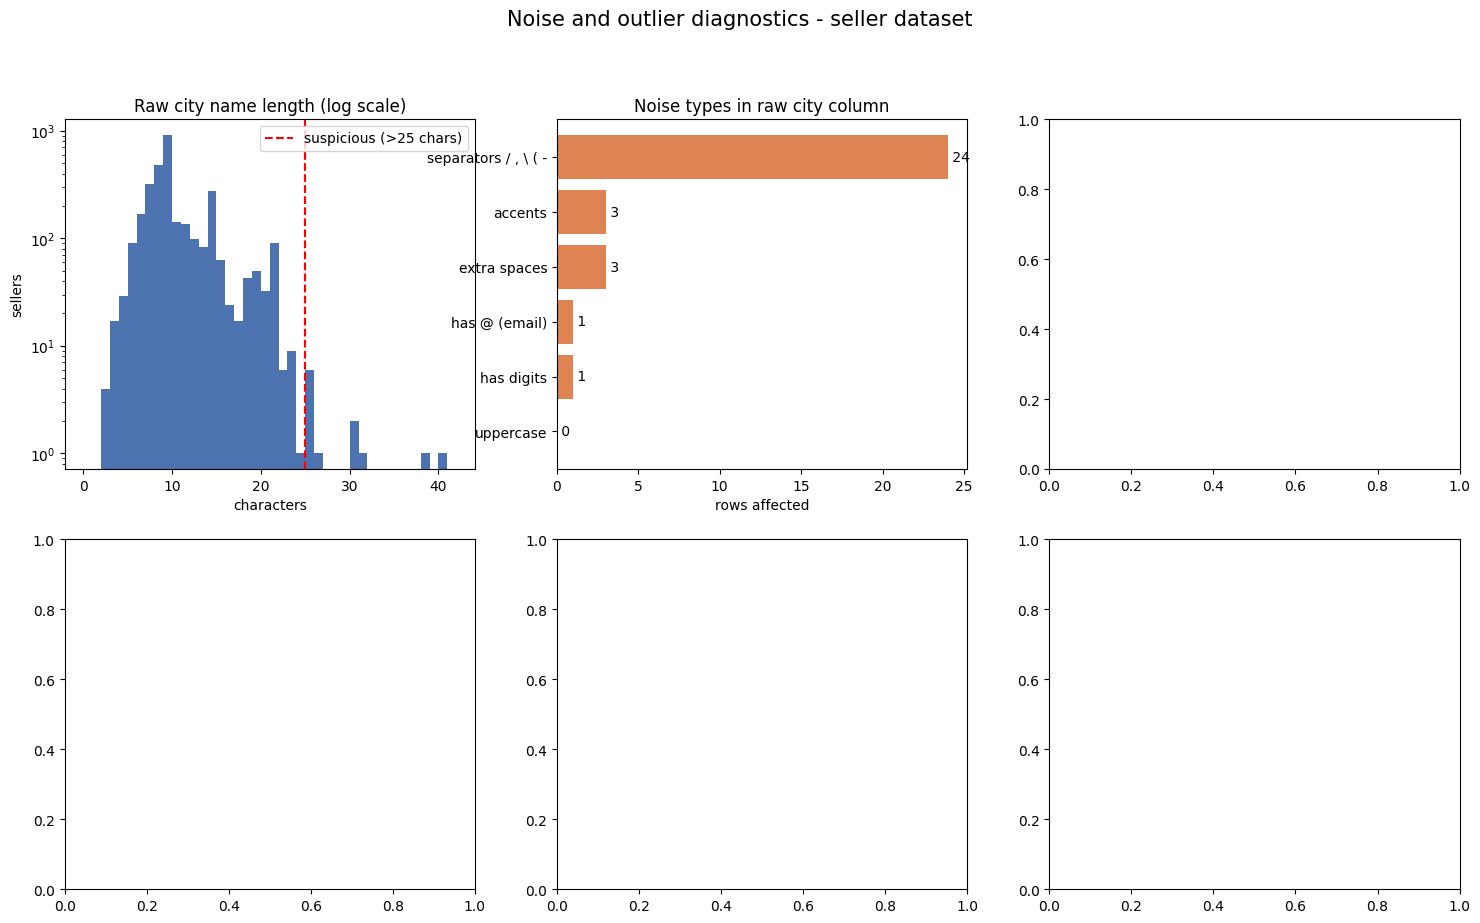

In [ ]:
# %% 8. VISUALS 1: noise and outliers (before vs after cleaning)
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Noise and outlier diagnostics - seller dataset', fontsize=15, y=0.99)

# (a) Length of the raw city string. Real city names are short; the long tail
#     is where e-mails, "city, state, country" and similar noise live.
lengths = data['city_raw'].str.len()
axes[0, 0].hist(lengths, bins=range(0, int(lengths.max()) + 3), color='#4c72b0')
axes[0, 0].axvline(25, color='red', ls='--', label='suspicious (>25 chars)')
axes[0, 0].set_yscale('log')
axes[0, 0].set_title('Raw city name length (log scale)')
axes[0, 0].set_xlabel('characters'); axes[0, 0].set_ylabel('sellers')
axes[0, 0].legend()
raw = data['city_raw']
noise = {
    'uppercase': (raw != raw.str.lower()).sum(),
    'extra spaces': (raw != raw.str.strip().str.replace(r'\s+', ' ', regex=True)).sum(),
    'accents': raw.map(lambda x: strip_accents(x) != x).sum(),
    'has digits': raw.str.contains(r'\d').sum(),
    'has @ (email)': raw.str.contains('@').sum(),
    'separators / , \\ ( -': raw.str.contains(r'[/\\,(\-]').sum(),
}
noise = pd.Series(noise).sort_values()
axes[0, 1].barh(noise.index, noise.values, color='#dd8452')
for i, v in enumerate(noise.values):
    axes[0, 1].text(v, i, f' {v}', va='center')
axes[0, 1].set_title('Noise types in raw city column')
axes[0, 1].set_xlabel('rows affected')






In [ ]:
# (c) Distinct city strings at each cleaning stage (fewer = more consistent).
stages = pd.Series({
    'raw': data['city_raw'].nunique(),
    'after rules': data['city_after_rules'].nunique(),
    'final': data['seller_city'].nunique(),
})
axes[0, 2].bar(stages.index, stages.values, color=['#c44e52', '#8172b3', '#55a868'])
for i, v in enumerate(stages.values):
    axes[0, 2].text(i, v, str(v), ha='center', va='bottom')
axes[0, 2].set_title('Distinct city strings per stage')



Text(0.5, 1.0, 'Distinct city strings per stage')

In [ ]:
# (d) Raw zip prefix per RAW state. A seller whose zip sits far from the rest of
#     its state box is an outlier = the state label does not match the zip.
order = data['state_raw'].str.upper().value_counts().index.tolist()
box_data = [pd.to_numeric(data.loc[data['state_raw'].str.upper() == s, 'zip_raw'],
                          errors='coerce').dropna() for s in order]
axes[1, 0].boxplot(box_data, flierprops=dict(marker='o', markersize=3, alpha=.6))
axes[1, 0].set_xticks(range(1, len(order) + 1))
axes[1, 0].set_xticklabels(order)
axes[1, 0].set_title('Zip prefix by ORIGINAL state (outliers = wrong state)')
axes[1, 0].set_ylabel('zip prefix (numeric)')
axes[1, 0].tick_params(axis='x', rotation=90)



In [ ]:
# (e) Which original states were corrected, and how many rows each.
fixed = data.loc[data['state_corrected'], 'state_raw'].str.upper().value_counts()
axes[1, 1].bar(fixed.index, fixed.values, color='#c44e52')
axes[1, 1].set_title(f"State corrected from zip ({data['state_corrected'].sum()} rows)\n"
                     "by ORIGINAL (wrong) state")
axes[1, 1].set_ylabel('rows')



Text(519.6483366842832, 0.5, 'rows')

In [ ]:
# (f) Long tail of cities: how many cities have only 1, 2, 3... sellers.
#     A huge group of 1-seller cities is a hint of remaining typos / low value
#     for one-hot encoding later.
freq = data['seller_city'].value_counts().value_counts().sort_index()
axes[1, 2].bar(freq.index.astype(str)[:15], freq.values[:15], color='#4c72b0')
axes[1, 2].set_title('Cities by number of sellers (first 15 bins)')
axes[1, 2].set_xlabel('sellers in the city'); axes[1, 2].set_ylabel('number of cities')

plt.tight_layout()
plt.show()




<Figure size 640x480 with 0 Axes>

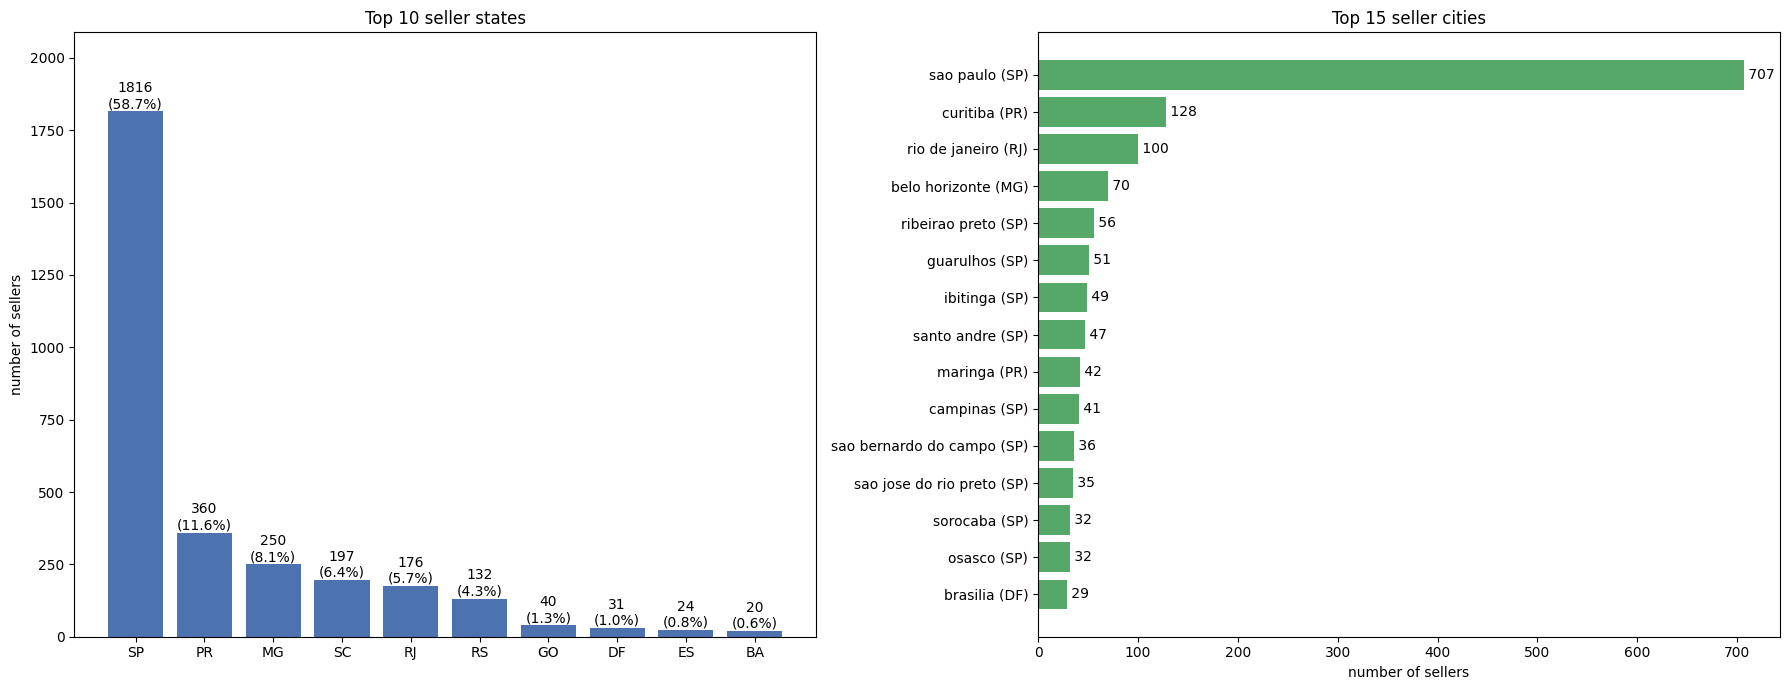

In [ ]:
# %% 9. VISUALS 2: top seller states and cities
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Top states (share of all sellers written on the bars).
top_states = data['seller_state'].value_counts().head(10)
share = top_states / len(data) * 100
axes[0].bar(top_states.index, top_states.values, color='#4c72b0')
for i, (v, p) in enumerate(zip(top_states.values, share.values)):
    axes[0].text(i, v, f'{v}\n({p:.1f}%)', ha='center', va='bottom')
axes[0].set_title('Top 10 seller states')
axes[0].set_ylabel('number of sellers')
axes[0].set_ylim(0, top_states.max() * 1.15)

# Top cities. Grouped by city AND state, because the same city name can
# exist in different states.
top_cities = (data.groupby(['seller_city', 'seller_state']).size()
                  .sort_values(ascending=False).head(15))
labels = [f'{c} ({s})' for c, s in top_cities.index][::-1]
axes[1].barh(labels, top_cities.values[::-1], color='#55a868')
for i, v in enumerate(top_cities.values[::-1]):
    axes[1].text(v, i, f' {v}', va='center')
axes[1].set_title('Top 15 seller cities')
axes[1].set_xlabel('number of sellers')

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/viz_top_states_cities.png', dpi=130)
plt.show()

In [ ]:
# %% 10. Export
# Clean file: same 4 columns as the original so it joins cleanly with the
# other tables.
clean_cols = ['seller_id', 'seller_zip_code_prefix', 'seller_city', 'seller_state']
data[clean_cols].to_csv(f'{OUTPUT_DIR}/clean_seller_0.csv', index=False)
print("saved clean_seller_0.csv")

# Download in Colab only (ignored when running locally).
try:
    from google.colab import files
    files.download('clean_seller_0.csv')
except ImportError:
    pass

saved clean_seller_0.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>